# TP Extension — Analyse de données télématiques (sans ML)
Durée indicative : **2h** (optionnel / extensions)

## Objectifs
- Explorer un dataset télématique (CSV) : taille, colonnes, types, manquants
- Visualiser un véhicule comme **série temporelle**
- Créer des **features métier** (conduite agressive, éco-conduite)
- Détecter des anomalies simples (sur-vitesse, glitch GPS) **sans machine learning**

> Dataset synthétique mais réaliste : bruit, outliers, valeurs manquantes.


## 0) Setup & lecture du dataset

Le fichier est dans `data/telematics.csv` (compatible JupyterHub).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/telematics.csv")
df.head()


: 

### ✅ TODO 0.1 — Premiers réflexes
1. Affichez `df.shape` (lignes, colonnes)
2. Affichez `df.columns`
3. Affichez `df.dtypes`
4. Calculez le % de valeurs manquantes par colonne

💡 Indice : `df.isna().mean() * 100`


In [7]:
# TODO 0.1
print("shape =", df.shape)
print("columns =", df.columns)
print("dtypes =", df.dtypes)

missing_pct = df.isna().mean() * 100
print(missing_pct)

shape = (14709, 10)
columns = Index(['vehicle_id', 'timestamp', 'speed_kmh', 'rpm', 'acc_x', 'brake',
       'gps_lat', 'gps_lon', 'fuel_rate_lph', 'engine_temp_c'],
      dtype='object')
dtypes = vehicle_id        object
timestamp         object
speed_kmh        float64
rpm              float64
acc_x            float64
brake              int64
gps_lat          float64
gps_lon          float64
fuel_rate_lph    float64
engine_temp_c    float64
dtype: object
vehicle_id       0.000000
timestamp        0.000000
speed_kmh        0.000000
rpm              0.299137
acc_x            0.000000
brake            0.000000
gps_lat          0.000000
gps_lon          0.000000
fuel_rate_lph    0.000000
engine_temp_c    0.000000
dtype: float64


## 1) Nettoyage minimal : dates & tri
On veut que `timestamp` soit un vrai type date/heure, puis on trie.


In [8]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(["vehicle_id", "timestamp"]).reset_index(drop=True)
df.head()


,vehicle_id,timestamp,speed_kmh,rpm,acc_x,brake,gps_lat,gps_lon,fuel_rate_lph,engine_temp_c
0,V001,2025-03-10 07:00:00,24.2,1720.0,-0.10,0,48.833062,2.301721,2.84,81.0
1,V001,2025-03-10 07:01:00,42.4,2078.0,0.14,0,48.832939,2.302878,3.51,87.0
2,V001,2025-03-10 07:02:00,45.8,2390.0,0.69,0,48.832788,2.304300,3.82,86.6
3,V001,2025-03-10 07:03:00,80.7,3097.0,-0.15,0,48.832675,2.307079,4.69,94.3
4,V001,2025-03-10 07:04:00,89.5,3768.0,1.03,0,48.832365,2.308517,5.87,101.0


### ✅ TODO 1.1 — Comprendre la période
1. Affichez le min/max de `timestamp`
2. Combien de véhicules ?
3. Combien d'échantillons par véhicule (top 5) ?

💡 Indices :
- `df["timestamp"].min()`
- `df["vehicle_id"].nunique()`
- `df["vehicle_id"].value_counts().head()`


In [9]:
# TODO 1.1
print("min timestamp =", df["timestamp"].min())
print("max timestamp =", df["vehicle_id"].nunique())
print("nb vehicles =", df["vehicle_id"].value_counts().head())
df["vehicle_id"].value_counts().head()


min timestamp = 2025-03-10 07:00:00
max timestamp = 18
nb vehicles = vehicle_id
V012    834
V002    832
V007    831
V003    830
V017    827
Name: count, dtype: int64


vehicle_id
V012    834
V002    832
V007    831
V003    830
V017    827
Name: count, dtype: int64

## 2) Un véhicule = une série temporelle

On sélectionne un véhicule et on observe son comportement.

In [17]:
vehicle = df["vehicle_id"].value_counts().index[0]
df_v = df[df["vehicle_id"] == vehicle].copy().sort_values("timestamp")
vehicle, df_v.shape


('V012', (834, 10))

### ✅ TODO 2.1 — Vitesse dans le temps
Tracez `speed_kmh` en fonction de `timestamp`.

Questions :
- Voyez-vous des phases arrêt/roulage ?
- Des pics suspects ?


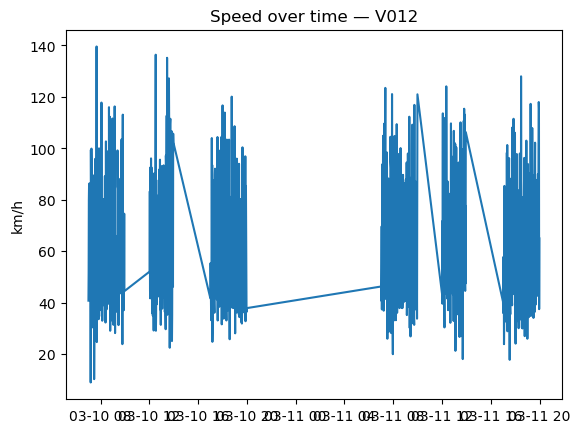

In [12]:
# TODO 2.1
plt.figure()
plt.plot(df_v["timestamp"], df_v["speed_kmh"])
plt.title(f"Speed over time — {vehicle}")
plt.ylabel("km/h")
plt.show()


### ✅ TODO 2.2 — Accélération & freinage
Tracez `acc_x` et `brake` sur le même graphique.

Astuce : multipliez `brake` par une constante (ex: 3) pour le rendre visible.


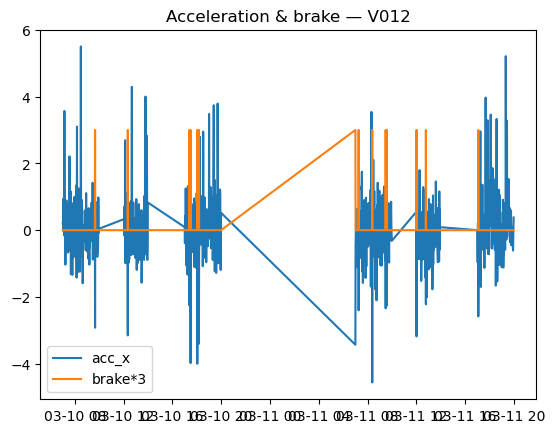

In [15]:
# TODO 2.2
plt.figure()
plt.plot(df_v["timestamp"], df_v["acc_x"], label="acc_x")
plt.plot(df_v["timestamp"], df_v["brake"]*3, label="brake*3")
plt.legend()
plt.title(f"Acceleration & brake — {vehicle}")
plt.show()


## 3) Feature engineering métier

### 3.1 Conduite agressive (harsh events)
On crée `harsh_event` si :
- acc_x > 2.5 **ou**
- freinage (brake==1) à vitesse > 50


In [16]:
df2 = df.copy()
df2["harsh_event"] = (
    (df2["acc_x"] > 2.5) |
    ((df2["brake"] == 1) & (df2["speed_kmh"] > 50))
)
df2[["vehicle_id","timestamp","speed_kmh","acc_x","brake","harsh_event"]].head()


,vehicle_id,timestamp,speed_kmh,acc_x,brake,harsh_event
0,V001,2025-03-10 07:00:00,24.2,-0.10,0,False
1,V001,2025-03-10 07:01:00,42.4,0.14,0,False
2,V001,2025-03-10 07:02:00,45.8,0.69,0,False
3,V001,2025-03-10 07:03:00,80.7,-0.15,0,False
4,V001,2025-03-10 07:04:00,89.5,1.03,0,False


### ✅ TODO 3.1 — Ranking agressivité
1. Taux d'harsh events par véhicule (`mean`)
2. Trier du plus agressif au plus calme
3. Afficher le top 5


In [24]:
# TODO 3.1
harsh_rate = df2.groupby(df2["vehicle_id"])["harsh_event"].mean()
harsh_rate_sorted = harsh_rate.sort_values(ascending = 0)
harsh_rate_sorted.head(5)


vehicle_id
V011    0.100737
V002    0.058894
V007    0.056558
V010    0.051345
V003    0.050602
Name: harsh_event, dtype: float64

### 3.2 Éco-conduite (eco events)
Règle simplifiée :
- vitesse entre 40 et 90
- rpm < 2500 (on remplace les NaN par la médiane)


In [ ]:
df2["eco_event"] = (
    df2["speed_kmh"].between(40, 90) &
    (df2["rpm"].fillna(df2["rpm"].median()) < 2500)
)
df2[["speed_kmh","rpm","eco_event"]].head()


### ✅ TODO 3.2 — Comparaison (eco_rate vs harsh_rate)
1. Calculez `eco_rate` par véhicule (mean)
2. Construisez un tableau `summary` avec eco_rate + harsh_rate
3. Scatter : x=eco_rate, y=harsh_rate

Interprétation attendue :
- bons conducteurs → eco_rate élevé, harsh_rate faible


In [ ]:
# TODO 3.2
eco_rate = None
summary = None
summary.head()


In [ ]:
# TODO 3.2 (plot)
plt.figure()
# plt.scatter(summary["eco_rate"], summary["harsh_rate"])
plt.xlabel("eco_rate")
plt.ylabel("harsh_rate")
plt.title("Eco vs Harsh per vehicle")
plt.show()


## 4) GPS : trajectoire simple
On trace longitude vs latitude pour visualiser la trajectoire.


In [ ]:
df_v2 = df2[df2["vehicle_id"] == vehicle].copy().sort_values("timestamp")

plt.figure()
plt.plot(df_v2["gps_lon"], df_v2["gps_lat"], ".-", markersize=2)
plt.title(f"GPS trajectory — {vehicle}")
plt.xlabel("lon")
plt.ylabel("lat")
plt.show()


### ✅ TODO 4.1 — Glitch GPS
1. Calculez les sauts successifs sur lat/lon (diff absolue)
2. Combinez en un score `jump = dlat + dlon`
3. Trouvez les 5 plus grands sauts et affichez les lignes correspondantes

💡 Indices : `diff().abs()`, `nlargest(5)`


In [ ]:
# TODO 4.1
dlat = None
dlon = None
jump = None
# jump.nlargest(5)


## 5) Anomalies simples

### 5.1 Sur-vitesse
On définit un seuil par quantile (99%).


In [ ]:
threshold = df2["speed_kmh"].quantile(0.99)
threshold


### ✅ TODO 5.1 — Événements de sur-vitesse
1. Filtrez speed_kmh > threshold
2. Comptez par véhicule
3. Affichez le top 5


In [ ]:
# TODO 5.1
overspeed = None
overspeed_counts = None
overspeed_counts.head(5)


## 6) Challenge final (différencié)

🟢 **Niveau 1**  
- Trouver le véhicule le plus agressif (harsh_rate max)
- Fournir 2 graphiques (vitesse + acc/brake)

🟡 **Niveau 2**  
- Créer `risk_score = harsh_rate + (1 - eco_rate)`
- Trier les véhicules

🔵 **Niveau 3 (pré-ML)**  
- Proposer une règle simple “calme vs agressif” (sans sklearn)
- Justifier (2-3 phrases)


In [ ]:
# TODO 6 (Niveau 2)
# summary["risk_score"] = ...
# summary.sort_values("risk_score", ascending=False).head(10)


## ✅ Checklist de fin
- [ ] Explorer un dataset télématique
- [ ] Visualiser une série temporelle
- [ ] Créer des features métier (harsh, eco)
- [ ] Ranking par véhicule
- [ ] Détection simple d'anomalies
